# Missed Signals: Does the hospital warning score miss patients?

**Problem.** Hospitals use NEWS2, a checklist score built from vital signs, to spot patients who are getting worse.
It uses fixed cutoffs and trusts the pulse oximeter. We test (1) what the datathon's Health Risk labels really are,
(2) whether a trained model catches sepsis earlier than NEWS2 at the same number of alarms, on a hospital the model
never saw, and (3) how a pulse-oximeter error changes who gets flagged.

**Advanced Track checklist**

| Requirement | Where |
|---|---|
| Model (trained) | Section 5: logistic regression and LightGBM trained on hospital A |
| Baseline | NEWS2 (published clinical rule) and majority class, Sections 3 and 5 |
| Held-out evaluation | Section 3: 30% held-out split. Section 6: hospital B, never used for training or tuning |
| Error and fairness analysis (3+ subgroups, failure examples) | Sections 3 and 7: oxygen scale, on oxygen, consciousness, sex, age group, ICU type; Section 8: missed patients |
| Data decisions, checked by hand | Section 2 (ID leak, NEWS2 hand-checks) and Section 4 (label and onset rules) |
| Reproducibility | Fixed seed 42, `requirements.txt`, raw data to results in this notebook |

**Data.** Health_Risk_Dataset.csv (datathon, Apache 2.0). PhysioNet/CinC Challenge 2019 sepsis data
(Reyna et al., CC BY 4.0): hourly ICU records from two hospital systems.

In [1]:
import glob
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score, average_precision_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
import lightgbm as lgb

sys.path.insert(0, os.path.abspath("."))
import news2 as N
import plots as P

SEED = 42
np.random.seed(SEED)
DATA = os.environ.get("DATA_DIR", "data")
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
P.style()
pd.set_option("display.width", 160)

## 1. Health Risk dataset: audit

In [2]:
hr = pd.read_csv(os.path.join(DATA, "Health_Risk_Dataset.csv"))
print(hr.shape)
print(hr.Risk_Level.value_counts())
hr.head()

(1000, 10)
Risk_Level
Medium    306
High      279
Low       255
Normal    160
Name: count, dtype: int64


,Patient_ID,Respiratory_Rate,Oxygen_Saturation,O2_Scale,Systolic_BP,Heart_Rate,Temperature,Consciousness,On_Oxygen,Risk_Level
0,P0522,25,96,1,97,107,37.5,A,0,Medium
1,P0738,28,92,2,116,151,38.5,P,1,High
2,P0741,29,91,1,79,135,38.4,A,0,High
3,P0661,24,96,1,95,92,37.3,A,0,Medium
4,P0412,20,96,1,97,97,37.4,A,0,Low


### 1a. Patient_ID leaks the label
The IDs follow risk order, so a model that sees the ID can score perfectly without learning anything clinical.
We drop the column before any modelling.

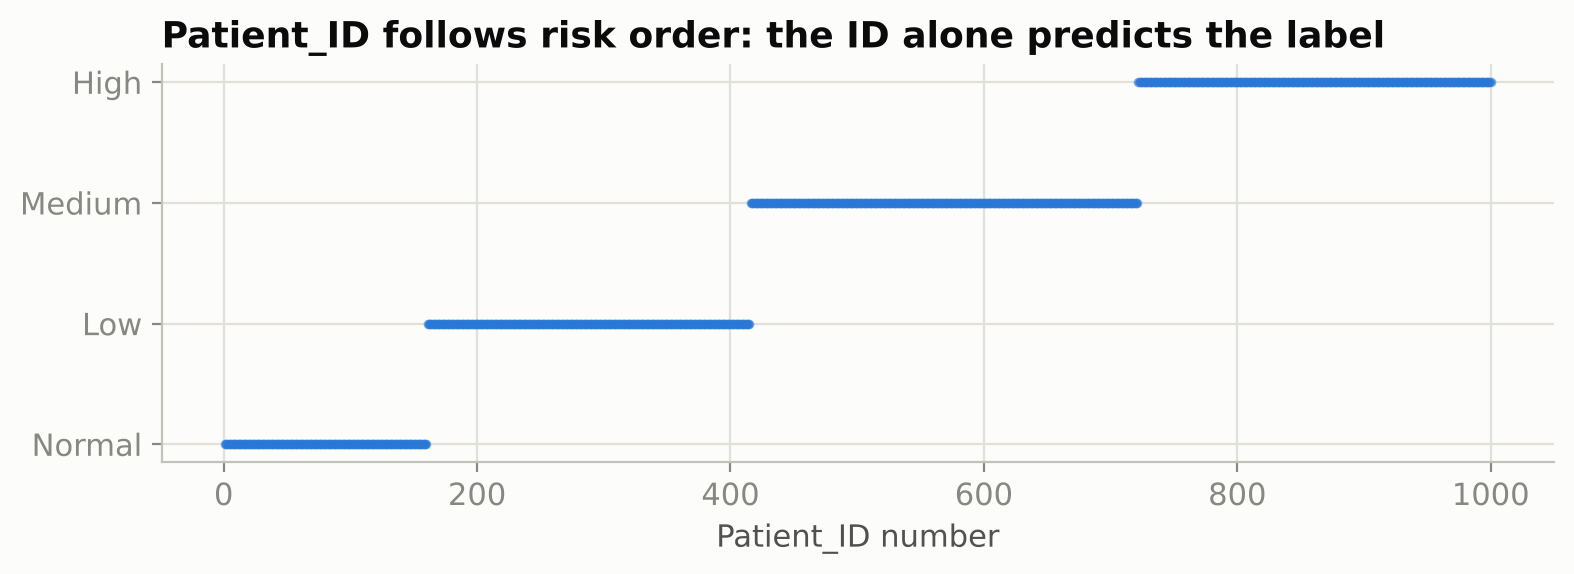

Accuracy from Patient_ID alone: 0.997


In [3]:
hr["id_num"] = hr.Patient_ID.str[1:].astype(int)
order = ["Normal", "Low", "Medium", "High"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(hr.id_num, hr.Risk_Level.map({k: i for i, k in enumerate(order)}), s=6, color=P.BLUE, alpha=0.6)
ax.set_yticks(range(4)); ax.set_yticklabels(order)
ax.set_xlabel("Patient_ID number"); ax.set_title("Patient_ID follows risk order: the ID alone predicts the label")
P.save(fig, f"{FIG}/fig1_id_leak.png"); plt.show()

Xid_tr, Xid_te, yid_tr, yid_te = train_test_split(hr[["id_num"]], hr.Risk_Level, test_size=0.3, random_state=SEED, stratify=hr.Risk_Level)
leak = lgb.LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(Xid_tr, yid_tr)
print("Accuracy from Patient_ID alone:", round(accuracy_score(yid_te, leak.predict(Xid_te)), 3))

### 1b. Are the labels just NEWS2?
We score every row with our NEWS2 function (`news2.py`, unit-tested on hand-checked rows) and map totals to bands:
0 = Normal, 1-4 = Low, 5-6 or any single vital scoring 3 = Medium, 7+ = High.

In [4]:
comp = N.news2_components(hr.Respiratory_Rate, hr.Oxygen_Saturation, hr.O2_Scale, hr.On_Oxygen,
                          hr.Systolic_BP, hr.Heart_Rate, hr.Consciousness, hr.Temperature)
hr["news2"] = N.news2_total(comp)
hr["news2_band"] = N.news2_band(comp)
agree = (hr.news2_band == hr.Risk_Level).mean()
print(f"NEWS2 band matches Risk_Level on {agree:.1%} of {len(hr)} rows")
print(pd.crosstab(hr.Risk_Level, hr.news2_band).reindex(index=order, columns=order))
mismatch = hr[hr.news2_band != hr.Risk_Level]
print("All mismatches are O2 scale 2, on room air, SpO2 93-96:",
      bool(((mismatch.O2_Scale == 2) & (mismatch.On_Oxygen == 0) & mismatch.Oxygen_Saturation.between(93, 96)).all()))
mismatch.head(20)

NEWS2 band matches Risk_Level on 98.7% of 1000 rows
news2_band  Normal  Low  Medium  High
Risk_Level                           
Normal         160    0       0     0
Low              0  255       0     0
Medium           0   13     293     0
High             0    0       0   279
All mismatches are O2 scale 2, on room air, SpO2 93-96: True


,Patient_ID,Respiratory_Rate,Oxygen_Saturation,O2_Scale,Systolic_BP,Heart_Rate,Temperature,Consciousness,On_Oxygen,Risk_Level,id_num,news2,news2_band
72,P0591,16,93,2,109,92,39.1,A,0,Medium,591,4.0,Low
150,P0644,24,96,2,106,98,38.0,A,0,Medium,644,4.0,Low
167,P0690,20,95,2,102,106,38.2,A,0,Medium,690,3.0,Low
205,P0597,24,95,2,108,106,38.0,A,0,Medium,597,4.0,Low
233,P0576,16,95,2,97,79,39.1,A,0,Medium,576,4.0,Low
312,P0582,21,93,2,118,106,38.3,A,0,Medium,582,4.0,Low
339,P0533,17,95,2,92,101,38.7,A,0,Medium,533,4.0,Low
479,P0594,22,93,2,108,88,38.5,A,0,Medium,594,4.0,Low
489,P0498,23,96,2,103,85,38.8,A,0,Medium,498,4.0,Low
579,P0626,18,94,2,108,103,39.2,A,0,Medium,626,4.0,Low


**Finding.** The labels are NEWS2: 987 of 1,000 rows match exactly. All 13 differences are scale-2 patients on room air
with SpO2 93-96, where the dataset scores SpO2 as if the patient were on oxygen. So a model trained on these labels can
only learn to copy NEWS2. To test whether anything beats NEWS2, we need real outcomes: PhysioNet (Section 4).

## 2. Health Risk models vs. baselines (30% held-out test)

In [5]:
feat = ["Respiratory_Rate", "Oxygen_Saturation", "O2_Scale", "Systolic_BP", "Heart_Rate", "Temperature", "On_Oxygen"]
X = hr[feat].copy()
X["alert"] = (hr.Consciousness == "A").astype(int)
y = hr.Risk_Level
X_tr, X_te, y_tr, y_te, idx_tr, idx_te = train_test_split(X, y, hr.index, test_size=0.3, random_state=SEED, stratify=y)

res = {}
res["Majority class"] = np.full(len(y_te), y_tr.mode()[0])
res["NEWS2 rule (no training)"] = hr.loc[idx_te, "news2_band"].to_numpy()
lr_hr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)).fit(X_tr, y_tr)
res["Logistic regression"] = lr_hr.predict(X_te)
gb_hr = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED, verbose=-1).fit(X_tr, y_tr)
res["LightGBM"] = gb_hr.predict(X_te)
tab = pd.DataFrame({k: {"accuracy": accuracy_score(y_te, v), "macro_F1": f1_score(y_te, v, average="macro"),
                        "High recall": ((v == "High") & (y_te == "High")).sum() / (y_te == "High").sum()}
                    for k, v in res.items()}).T.round(3)
tab

,accuracy,macro_F1,High recall
Majority class,0.307,0.117,0.000
NEWS2 rule (no training),0.993,0.994,1.000
Logistic regression,0.967,0.967,0.976
LightGBM,0.967,0.969,0.976


### 2a. Subgroups (fairness) on the held-out set
Oxygen scale 2 marks patients with chronic lung disease; consciousness and oxygen use mark sicker patients.

In [6]:
te = hr.loc[idx_te].copy()
te["pred_lgbm"] = res["LightGBM"]; te["pred_lr"] = res["Logistic regression"]
groups = {"O2 scale": te.O2_Scale.map({1: "Scale 1", 2: "Scale 2 (lung disease)"}),
          "On oxygen": te.On_Oxygen.map({0: "Room air", 1: "On oxygen"}),
          "Consciousness": np.where(te.Consciousness == "A", "Alert", "Not alert (C/V/P/U)")}
rows = []
for gname, g in groups.items():
    for lvl in pd.Series(g).unique():
        m = np.asarray(g == lvl)
        for model in ["pred_lr", "pred_lgbm"]:
            rows.append({"subgroup": gname, "level": lvl, "model": model, "n": m.sum(),
                         "macro_F1": f1_score(te.Risk_Level[m], te[model][m], average="macro")})
pd.DataFrame(rows).pivot_table(index=["subgroup", "level", "n"], columns="model", values="macro_F1").round(3)

model                                     pred_lgbm  pred_lr
subgroup      level                  n                      
Consciousness Alert                  269      0.970    0.965
              Not alert (C/V/P/U)    31       0.630    1.000
O2 scale      Scale 1                271      0.966    0.964
              Scale 2 (lung disease) 29       1.000    1.000
On oxygen     On oxygen              81       0.906    1.000
              Room air               219      0.976    0.957

## 3. Pulse-oximeter bias test (Health Risk)
Pulse oximeters can overestimate oxygen on darker skin (Sjoding et al., NEJM 2020). We add +2, +3 and +4 points
to every SpO2 reading (capped at 100) and count how many patients drop to a lower band.

In [7]:
bias_rows = []
for shift in [0, 2, 3, 4]:
    c = N.news2_components(hr.Respiratory_Rate, np.minimum(hr.Oxygen_Saturation + shift, 100), hr.O2_Scale, hr.On_Oxygen,
                           hr.Systolic_BP, hr.Heart_Rate, hr.Consciousness, hr.Temperature)
    b = pd.Series(N.news2_band(c))
    rank = {k: i for i, k in enumerate(order)}
    base = hr.news2_band.map(rank); new = b.map(rank)
    bias_rows.append({"SpO2 shift": f"+{shift}", "High patients": (b == "High").sum(),
                      "patients moved to a lower band": int((new < base).sum()),
                      "High -> lower": int(((hr.news2_band == "High") & (b != "High")).sum()),
                      "Medium -> Low/Normal": int(((hr.news2_band == "Medium") & b.isin(["Low", "Normal"])).sum())})
bias_hr = pd.DataFrame(bias_rows)
bias_hr

,SpO2 shift,High patients,patients moved to a lower band,High -> lower,Medium -> Low/Normal
0,+0,279,0,0,0
1,+2,285,111,1,78
2,+3,287,155,1,117
3,+4,292,195,1,153


## 4. PhysioNet 2019: real outcomes over time
**Data decisions.**
* One file per ICU stay, one row per hour. Hospital A = `training_setA`, hospital B = `training_setB`.
* We use the 5 vitals both datasets share (HR, O2Sat, Temp, SBP, Resp), plus FiO2 > 0.21 as "on oxygen",
  age and sex. PhysioNet has no consciousness score, so NEWS2 assumes "Alert" (this favours NEWS2 slightly less).
* Vitals are carried forward within a stay. Hours before HR, O2Sat, SBP and Resp all exist are dropped.
* `SepsisLabel` turns 1 six hours **before** clinical onset (challenge definition). Onset = first labelled hour + 6.
* For early-warning metrics we keep sepsis patients with at least 12 observed hours before onset.

In [8]:
def load_set(folder, hospital):
    cache = os.path.join(DATA, f"physionet_{hospital}.parquet")
    if os.path.exists(cache):
        return pd.read_parquet(cache)
    files = sorted(glob.glob(os.path.join(folder, "*.psv")))
    parts = []
    for f in files:
        d = pd.read_csv(f, sep="|", usecols=["HR", "O2Sat", "Temp", "SBP", "Resp", "FiO2", "Age", "Gender",
                                            "Unit1", "Unit2", "ICULOS", "SepsisLabel"])
        d["pid"] = hospital + os.path.basename(f)[1:-4]
        parts.append(d)
    out = pd.concat(parts, ignore_index=True)
    out["hospital"] = hospital
    out.to_parquet(cache)
    return out


setA = glob.glob(os.path.join(DATA, "**", "training_setA"), recursive=True)
setB = glob.glob(os.path.join(DATA, "**", "training_setB"), recursive=True)
ph = pd.concat([load_set(setA[0], "A"), load_set(setB[0], "B")], ignore_index=True)
ph = ph.sort_values(["pid", "ICULOS"]).reset_index(drop=True)
per_stay = ph.groupby("pid").agg(hospital=("hospital", "first"), septic=("SepsisLabel", "max"), hours=("ICULOS", "size"))
print(per_stay.groupby("hospital").agg(stays=("septic", "size"), septic_stays=("septic", "sum"), hours=("hours", "sum")))

          stays  septic_stays   hours
hospital                             
A         20336          1790  790215
B         20000          1142  761995


In [9]:
VITALS = ["HR", "O2Sat", "Temp", "SBP", "Resp"]


def build_features(df, spo2_shift=0):
    d = df.copy()
    if spo2_shift:
        d["O2Sat"] = np.minimum(d.O2Sat + spo2_shift, 100)
    g = d.groupby("pid", sort=False)
    d[VITALS + ["FiO2"]] = g[VITALS + ["FiO2"]].ffill()
    k = g.cumcount()
    for v in VITALS:
        s = d[v]
        roll_max = s.rolling(6, min_periods=1).max(); roll_min = s.rolling(6, min_periods=1).min()
        exp_max = g[v].cummax(); exp_min = g[v].cummin()
        d[f"{v}_max6"] = np.where(k < 5, exp_max, roll_max)
        d[f"{v}_min6"] = np.where(k < 5, exp_min, roll_min)
        d[f"{v}_d6"] = s - g[v].shift(6)
    d["on_o2"] = (d.FiO2 > 0.21).astype(int)
    d["male"] = d.Gender.fillna(0).astype(int)
    comp = N.news2_components(d.Resp, d.O2Sat, 1, d.on_o2, d.SBP, d.HR, np.full(len(d), "A"), d.Temp)
    d["news2"] = N.news2_total(comp)
    keep = d[["HR", "O2Sat", "SBP", "Resp"]].notna().all(axis=1)
    return d[keep].copy()


feats = build_features(ph)
FEATS = VITALS + [f"{v}_{s}" for v in VITALS for s in ["max6", "min6", "d6"]] + ["on_o2", "Age", "male", "ICULOS"]
A = feats[feats.hospital == "A"]; B = feats[feats.hospital == "B"]
print("hours A:", len(A), " hours B:", len(B))

hours A: 749139  hours B: 728243


## 5. Models (trained on hospital A only)

In [10]:
lr = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                   LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
lr.fit(A[FEATS], A.SepsisLabel)
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, random_state=SEED, verbose=-1)
gbm.fit(A[FEATS], A.SepsisLabel)
# Ablation: same model without time in ICU (ICULOS), to show how much of the gain is vital signs alone
FEATS_V = [f for f in FEATS if f != "ICULOS"]
gbm_v = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=SEED, verbose=-1).fit(A[FEATS_V], A.SepsisLabel)

# Alarm budget: NEWS2 >= 5 (urgent-response trigger). Model thresholds are set on hospital A so each model
# raises the SAME share of hourly alarms as NEWS2 does on A. Nothing is tuned on hospital B.
pA_lr = lr.predict_proba(A[FEATS])[:, 1]; pA_gb = gbm.predict_proba(A[FEATS])[:, 1]
pA_v = gbm_v.predict_proba(A[FEATS_V])[:, 1]
BUDGETS = {}
for cut in [5, 7]:
    rate = (A.news2 >= cut).mean()
    BUDGETS[cut] = {"rate": rate, "thr_lr": np.quantile(pA_lr, 1 - rate), "thr_gb": np.quantile(pA_gb, 1 - rate),
                    "thr_v": np.quantile(pA_v, 1 - rate)}
    print(f"NEWS2>={cut} alarm rate on A: {rate:.2%} of hours")
alarm_rate = BUDGETS[5]["rate"]; thr_lr = BUDGETS[5]["thr_lr"]; thr_gb = BUDGETS[5]["thr_gb"]

NEWS2>=5 alarm rate on A: 30.56% of hours
NEWS2>=7 alarm rate on A: 10.00% of hours


## 6. Results on hospital B (never seen in training or tuning)

In [11]:
B = B.copy()
B["p_lr"] = lr.predict_proba(B[FEATS])[:, 1]
B["p_gb"] = gbm.predict_proba(B[FEATS])[:, 1]
B["p_v"] = gbm_v.predict_proba(B[FEATS_V])[:, 1]
B["alert_v"] = B.p_v >= BUDGETS[5]["thr_v"]
B["alert_news2"] = B.news2 >= 5
B["alert_lr"] = B.p_lr >= thr_lr
B["alert_gb"] = B.p_gb >= thr_gb

hour_tab = pd.DataFrame({
    "NEWS2 (score)": [roc_auc_score(B.SepsisLabel, B.news2), average_precision_score(B.SepsisLabel, B.news2)],
    "Logistic regression": [roc_auc_score(B.SepsisLabel, B.p_lr), average_precision_score(B.SepsisLabel, B.p_lr)],
    "LightGBM": [roc_auc_score(B.SepsisLabel, B.p_gb), average_precision_score(B.SepsisLabel, B.p_gb)],
    "LightGBM, vitals only (no ICU time)": [roc_auc_score(B.SepsisLabel, B.p_v), average_precision_score(B.SepsisLabel, B.p_v)],
}, index=["AUROC (hourly)", "AUPRC (hourly)"]).T.round(3)
print("Majority-class baseline: AUROC 0.5, AUPRC =", round(B.SepsisLabel.mean(), 3))
hour_tab

Majority-class baseline: AUROC 0.5, AUPRC = 0.014


,AUROC (hourly),AUPRC (hourly)
NEWS2 (score),0.701,0.034
Logistic regression,0.757,0.062
LightGBM,0.784,0.070
"LightGBM, vitals only (no ICU time)",0.725,0.043


In [12]:
def patient_metrics(df, alert_col, window=12):
    """Early warning per stay. Sepsis stays: alarm in the `window` hours before onset. Others: alarms per day."""
    out = {}
    first_lab = df[df.SepsisLabel == 1].groupby("pid").ICULOS.min()
    onset = first_lab + 6
    start = df.groupby("pid").ICULOS.min()
    eligible = onset[(onset - start.reindex(onset.index)) >= window]
    sep = df[df.pid.isin(eligible.index)].copy()
    sep["onset"] = sep.pid.map(eligible)
    win = sep[(sep.ICULOS < sep.onset) & (sep.ICULOS >= sep.onset - window)]
    caught = win.groupby("pid")[alert_col].any()
    first_alarm = win[win[alert_col]].groupby("pid").ICULOS.min()
    lead = (eligible.reindex(first_alarm.index) - first_alarm)
    non = df[~df.pid.isin(first_lab.index)]
    out["sepsis stays caught before onset"] = caught.mean()
    out["median hours of warning"] = lead.median()
    out["n sepsis stays"] = len(eligible)
    out["false alarms per patient-day"] = non[alert_col].sum() / (len(non) / 24)
    out["non-sepsis stays ever alarmed"] = non.groupby("pid")[alert_col].any().mean()
    return out, caught


pt = {}
caught = {}
for name, col in [("NEWS2 >= 5", "alert_news2"), ("Logistic regression", "alert_lr"), ("LightGBM", "alert_gb"),
                  ("LightGBM, vitals only", "alert_v")]:
    pt[name], caught[name] = patient_metrics(B, col)
pt_tab = pd.DataFrame(pt).T
# Stricter budget: the NEWS2 emergency-response trigger (>= 7)
b7 = BUDGETS[7]
B["a7_news2"] = B.news2 >= 7; B["a7_lr"] = B.p_lr >= b7["thr_lr"]; B["a7_gb"] = B.p_gb >= b7["thr_gb"]
B["a7_v"] = B.p_v >= b7["thr_v"]
pt7 = {n: patient_metrics(B, c)[0] for n, c in [("NEWS2 >= 7", "a7_news2"), ("Logistic regression", "a7_lr"), ("LightGBM", "a7_gb"),
                                                ("LightGBM, vitals only", "a7_v")]}
pt7_tab = pd.DataFrame(pt7).T
print("Alarm budget = NEWS2 >= 5 (urgent response)"); print(pt_tab.round(3).to_string())
print("\nAlarm budget = NEWS2 >= 7 (emergency response)"); print(pt7_tab.round(3).to_string())

Alarm budget = NEWS2 >= 5 (urgent response)
                       sepsis stays caught before onset  median hours of warning  n sepsis stays  false alarms per patient-day  non-sepsis stays ever alarmed
NEWS2 >= 5                                        0.782                     12.0           788.0                         4.182                          0.595
Logistic regression                               0.816                     12.0           788.0                         3.925                          0.477
LightGBM                                          0.838                     12.0           788.0                         4.797                          0.637
LightGBM, vitals only                             0.754                     12.0           788.0                         3.988                          0.497

Alarm budget = NEWS2 >= 7 (emergency response)
                       sepsis stays caught before onset  median hours of warning  n sepsis stays  false alarms per pat

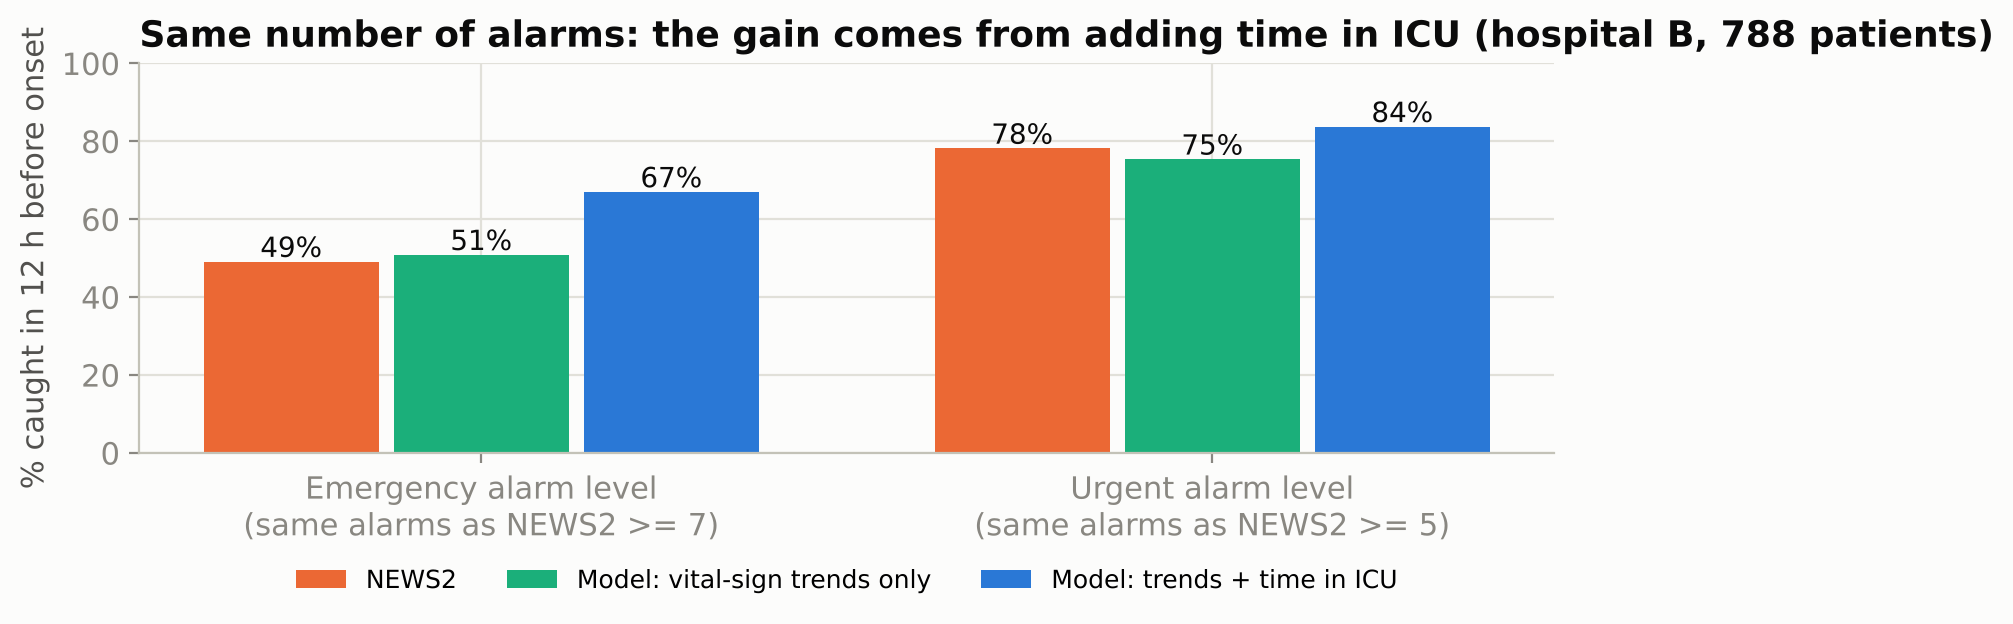

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = ["NEWS2", "Model: vital-sign trends only", "Model: trends + time in ICU"]
order5 = ["NEWS2 >= 5", "LightGBM, vitals only", "LightGBM"]; order7 = ["NEWS2 >= 7", "LightGBM, vitals only", "LightGBM"]
v5 = pt_tab.loc[order5, "sepsis stays caught before onset"].to_numpy() * 100
v7 = pt7_tab.loc[order7, "sepsis stays caught before onset"].to_numpy() * 100
x = np.arange(2); w = 0.26
for i, (lab, col) in enumerate(zip(labels, [P.ORANGE, P.AQUA, P.BLUE])):
    vals = [v7[i], v5[i]]
    bars = ax.bar(x + (i - 1) * w, vals, w * 0.92, color=col, label=lab)
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 1.2, f"{v:.0f}%", ha="center", color=P.INK, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels([f"Emergency alarm level\n(same alarms as NEWS2 >= 7)", f"Urgent alarm level\n(same alarms as NEWS2 >= 5)"])
ax.set_ylim(0, 100); ax.set_ylabel("% caught in 12 h before onset")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=3, fontsize=9)
ax.set_title("Same number of alarms: the gain comes from adding time in ICU (hospital B, 788 patients)")
P.save(fig, f"{FIG}/fig2_caught.png"); plt.show()

**Reading the results.** Models are compared with NEWS2 at the *same number of alarms*, set on hospital A and applied
unchanged to hospital B. A model built on vital-sign trends alone roughly matches NEWS2 with slightly fewer false alarms.
Most of the gain comes from adding time in ICU (`ICULOS`), the model's strongest feature. Sepsis risk in this data
rises with length of stay, and NEWS2 ignores it. This is information staff have at the bedside, but it is also a
feature that can reflect how this dataset was collected, so we report both models.

## 7. Fairness: subgroups on hospital B

In [14]:
def age_group(a):
    return pd.cut(a, [0, 45, 65, 80, 200], right=False, labels=["<45", "45-64", "65-79", "80+"])


stay = B.groupby("pid").agg(male=("male", "first"), Age=("Age", "first"), Unit1=("Unit1", "first"), Unit2=("Unit2", "first"))
stay["Sex"] = np.where(stay.male == 1, "Male", "Female")
stay["Age group"] = age_group(stay.Age)
stay["ICU type"] = np.select([stay.Unit1 == 1, stay.Unit2 == 1], ["Medical ICU", "Surgical ICU"], "Unknown")
fair = []
for sub in ["Sex", "Age group", "ICU type"]:
    for lvl, ids in stay.groupby(sub, observed=True).groups.items():
        row = {"subgroup": sub, "level": lvl}
        for name in caught:
            c = caught[name].reindex(ids).dropna()
            row[f"{name}: caught"] = c.mean() if len(c) else np.nan
        row["n sepsis stays"] = caught["LightGBM"].reindex(ids).notna().sum()
        hb = B[B.pid.isin(ids)]
        row["LightGBM AUROC (hourly)"] = roc_auc_score(hb.SepsisLabel, hb.p_gb) if hb.SepsisLabel.nunique() > 1 else np.nan
        fair.append(row)
fair_tab = pd.DataFrame(fair)
fair_tab.round(3)

,subgroup,level,NEWS2 >= 5: caught,Logistic regression: caught,LightGBM: caught,"LightGBM, vitals only: caught",n sepsis stays,LightGBM AUROC (hourly)
0,Sex,Female,0.788,0.817,0.846,0.762,345,0.798
1,Sex,Male,0.777,0.815,0.831,0.747,443,0.773
2,Age group,<45,0.727,0.797,0.828,0.617,128,0.788
3,Age group,45-64,0.814,0.818,0.825,0.763,291,0.779
4,Age group,65-79,0.781,0.834,0.859,0.795,283,0.789
5,Age group,80+,0.756,0.779,0.826,0.791,86,0.788
6,ICU type,Medical ICU,0.824,0.803,0.815,0.738,233,0.768
7,ICU type,Surgical ICU,0.827,0.851,0.875,0.796,329,0.783
8,ICU type,Unknown,0.673,0.779,0.805,0.708,226,0.806


## 8. Where the model fails
Sepsis stays the model missed in the 12 hours before onset, with the vitals at the last hour before onset.

In [15]:
missed_ids = caught["LightGBM"][~caught["LightGBM"]].index
lastrow = B[B.pid.isin(missed_ids)].sort_values("ICULOS").groupby("pid").last()
print("Missed by LightGBM:", len(missed_ids), "of", len(caught["LightGBM"]))
print("Of those, also missed by NEWS2:", (~caught["NEWS2 >= 5"].reindex(missed_ids)).sum())
lastrow[VITALS + ["news2", "p_gb", "Age"]].head(8).round(2)

Missed by LightGBM: 128 of 788
Of those, also missed by NEWS2: 61


,HR,O2Sat,Temp,SBP,Resp,news2,p_gb,Age
pid,,,,,,,,
B100088,107.0,98.0,36.6,112.0,14.0,3.0,0.01,68.0
B100462,88.0,94.0,37.9,138.0,24.0,5.0,0.02,40.0
B100527,90.0,99.5,36.5,120.0,10.0,3.0,0.02,74.0
B100612,123.5,91.5,38.6,121.0,26.0,10.0,0.10,64.0
B100671,80.0,95.0,37.3,113.0,9.0,4.0,0.01,75.0
B100811,98.0,99.0,37.7,131.0,14.0,1.0,0.02,60.0
B100823,64.0,98.0,37.2,98.0,16.0,4.0,0.01,57.0
B100838,81.0,100.0,37.1,143.0,10.0,3.0,0.00,18.0


## 9. Pulse-oximeter bias test on real outcomes
Same models and thresholds; every SpO2 reading in hospital B is raised by 3 points before scoring.

In [16]:
Bs = build_features(ph[ph.hospital == "B"], spo2_shift=3)
Bs["alert_news2"] = Bs.news2 >= 5
Bs["alert_gb"] = gbm.predict_proba(Bs[FEATS])[:, 1] >= thr_gb
Bs["alert_lr"] = lr.predict_proba(Bs[FEATS])[:, 1] >= thr_lr
bias_ph = []
for name, col in [("NEWS2 >= 5", "alert_news2"), ("Logistic regression", "alert_lr"), ("LightGBM", "alert_gb")]:
    m, c = patient_metrics(Bs, col)
    bias_ph.append({"method": name, "caught (true SpO2)": pt[name]["sepsis stays caught before onset"],
                    "caught (SpO2 +3)": m["sepsis stays caught before onset"],
                    "false alarms/day (true)": pt[name]["false alarms per patient-day"],
                    "false alarms/day (SpO2 +3)": m["false alarms per patient-day"]})
bias_ph = pd.DataFrame(bias_ph)
bias_ph["drop (points)"] = (bias_ph["caught (true SpO2)"] - bias_ph["caught (SpO2 +3)"]) * 100
bias_ph.round(3)

,method,caught (true SpO2),caught (SpO2 +3),false alarms/day (true),false alarms/day (SpO2 +3),drop (points)
0,NEWS2 >= 5,0.782,0.728,4.182,3.353,5.330
1,Logistic regression,0.816,0.813,3.925,3.979,0.254
2,LightGBM,0.838,0.859,4.797,4.904,-2.157


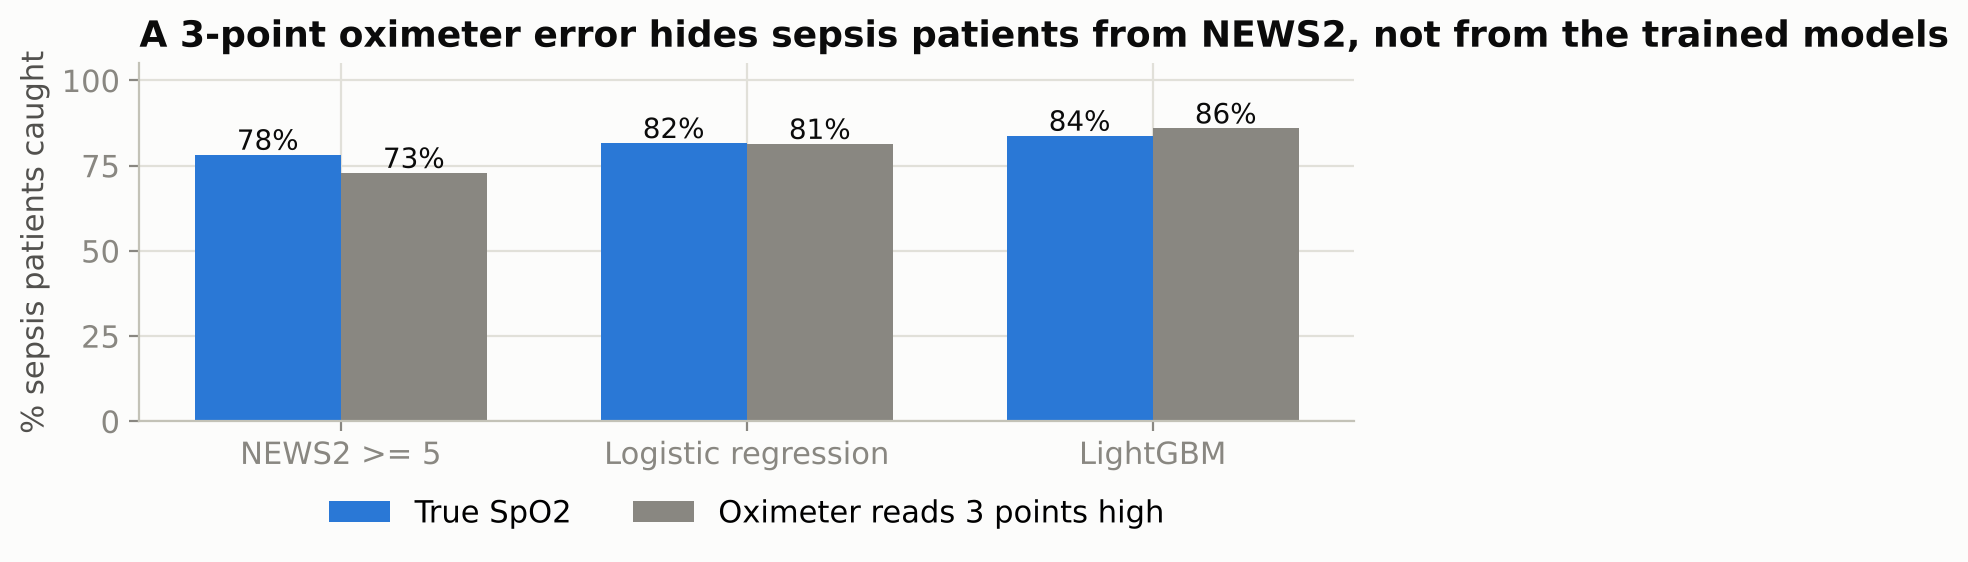

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(bias_ph)); w = 0.36
ax.bar(x - w / 2, bias_ph["caught (true SpO2)"] * 100, w, color=P.BLUE, label="True SpO2")
ax.bar(x + w / 2, bias_ph["caught (SpO2 +3)"] * 100, w, color=P.MUTED, label="Oximeter reads 3 points high")
ax.set_xticks(x); ax.set_xticklabels(bias_ph.method)
for i, r_ in bias_ph.iterrows():
    ax.text(i - w / 2, r_["caught (true SpO2)"] * 100 + 1.5, f"{r_['caught (true SpO2)']*100:.0f}%", ha="center", fontsize=10, color=P.INK)
    ax.text(i + w / 2, r_["caught (SpO2 +3)"] * 100 + 1.5, f"{r_['caught (SpO2 +3)']*100:.0f}%", ha="center", fontsize=10, color=P.INK)
ax.set_ylim(0, 105); ax.set_ylabel("% sepsis patients caught")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=2)
ax.set_title("A 3-point oximeter error hides sepsis patients from NEWS2, not from the trained models")
P.save(fig, f"{FIG}/fig3_oximeter_bias.png"); plt.show()

## 10. What drives the model, and one patient replay (demo)

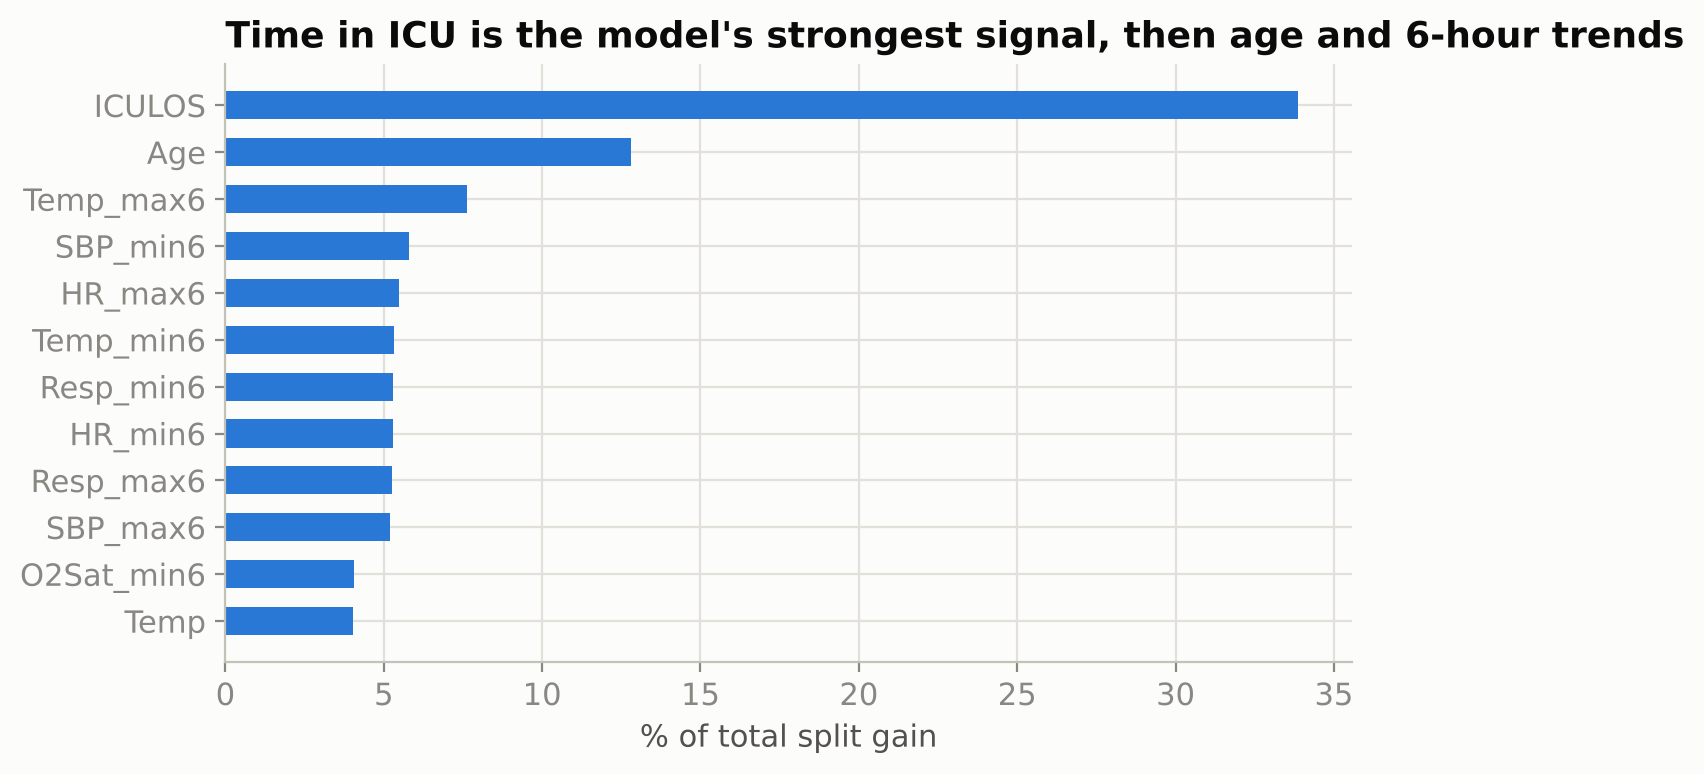

In [18]:
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=FEATS).sort_values(ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values / imp.values.sum() * 100, color=P.BLUE, height=0.6)
ax.set_xlabel("% of total split gain"); ax.set_title("Time in ICU is the model's strongest signal, then age and 6-hour trends")
P.save(fig, f"{FIG}/fig4_importance.png"); plt.show()

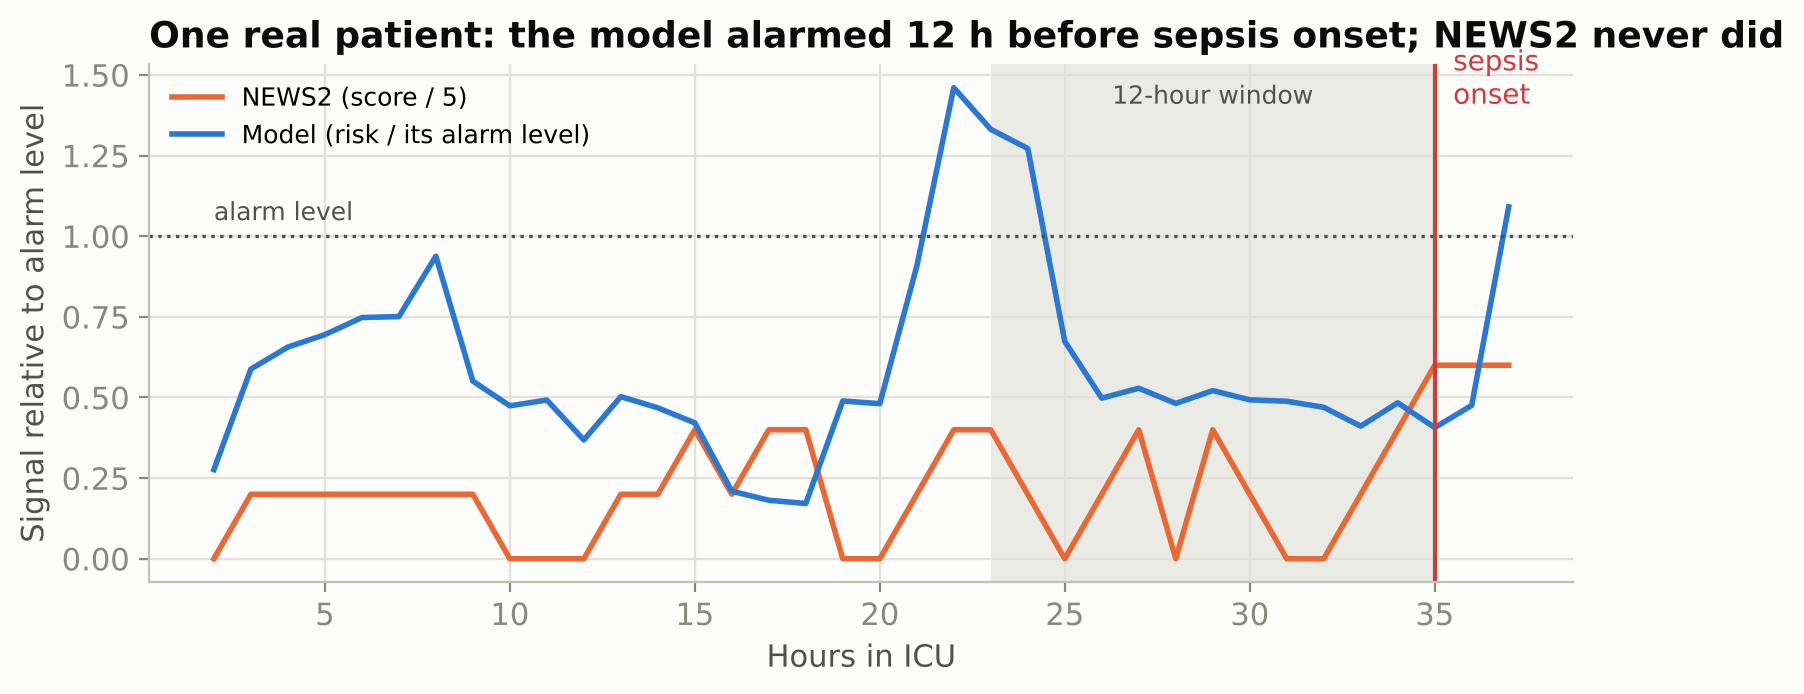

demo patient B119059 lead hours 12


In [19]:
# Demo patient: caught by the model, missed by NEWS2, longest warning inside the 12-hour window
first_lab = B[B.SepsisLabel == 1].groupby("pid").ICULOS.min()
cands = []
for p_ in caught["LightGBM"].index:
    if caught["LightGBM"][p_] and not caught["NEWS2 >= 5"].get(p_, False):
        on = first_lab[p_] + 6
        dd = B[B.pid == p_]
        w_ = dd[(dd.ICULOS < on) & (dd.ICULOS >= on - 12) & dd.alert_gb]
        before = dd[dd.ICULOS < on - 12]
        quiet = before.alert_gb.mean() if len(before) >= 12 else 1.0
        if quiet <= 0.05 and not dd[dd.ICULOS < on].alert_news2.any():
            cands.append((on - w_.ICULOS.min(), p_))
lead_h, demo_pid = max(cands)
d = B[B.pid == demo_pid]
onset_h = first_lab[demo_pid] + 6
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(onset_h - 12, onset_h, color=P.GRID, alpha=0.6, lw=0)
ax.plot(d.ICULOS, d.news2 / 5, color=P.ORANGE, label="NEWS2 (score / 5)")
ax.plot(d.ICULOS, d.p_gb / thr_gb, color=P.BLUE, label="Model (risk / its alarm level)")
ax.axhline(1, color=P.INK2, ls=":", lw=1.2)
ax.text(d.ICULOS.min(), 1.05, "alarm level", color=P.INK2, fontsize=9)
ax.axvline(onset_h, color=P.CRITICAL, lw=1.5)
ax.text(onset_h + 0.5, ax.get_ylim()[1] * 0.92, "sepsis\nonset", color=P.CRITICAL, ha="left", fontsize=10)
ax.text(onset_h - 6, ax.get_ylim()[1] * 0.92, "12-hour window", color=P.INK2, fontsize=9, ha="center")
ax.set_xlabel("Hours in ICU"); ax.set_ylabel("Signal relative to alarm level")
ax.legend(loc="upper left", fontsize=9)
ax.set_title(f"One real patient: the model alarmed {lead_h:.0f} h before sepsis onset; NEWS2 never did")
P.save(fig, f"{FIG}/fig5_patient_replay.png"); plt.show()
print("demo patient", demo_pid, "lead hours", lead_h)

## 11. Export for the app

In [20]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({"gbm": gbm, "lr": lr, "thr_gb": thr_gb, "thr_lr": thr_lr, "feats": FEATS}, "models/sepsis_models.joblib")
summary = {"health_risk_news2_agreement": agree, "alarm_rate_news2_5": BUDGETS[5]["rate"], "alarm_rate_news2_7": BUDGETS[7]["rate"],
           **{f"caught@5 {k}": v for k, v in pt_tab["sepsis stays caught before onset"].items()},
           **{f"caught@7 {k}": v for k, v in pt7_tab["sepsis stays caught before onset"].items()}}
pd.Series(summary).to_csv("figures/summary.csv")
summary

{'health_risk_news2_agreement': np.float64(0.987),
 'alarm_rate_news2_5': np.float64(0.30560016231967635),
 'alarm_rate_news2_7': np.float64(0.10002015647296429),
 'caught@5 NEWS2 >= 5': 0.7817258883248731,
 'caught@5 Logistic regression': 0.815989847715736,
 'caught@5 LightGBM': 0.8375634517766497,
 'caught@5 LightGBM, vitals only': 0.7538071065989848,
 'caught@7 NEWS2 >= 7': 0.49111675126903553,
 'caught@7 Logistic regression': 0.6053299492385786,
 'caught@7 LightGBM': 0.6700507614213198,
 'caught@7 LightGBM, vitals only': 0.5088832487309645}